# Tugas Praktikum Pertemuan 11 - Modifikasi dan Perbandingan CNN 1D pada Dataset PBL

## 1. Modifikasi Model CNN 1D dengan BatchNormalization, Dropout, dan ReduceLROnPlateau (3 Kelas)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Load seluruh 50.000 data PBL
df = pd.read_csv('burnout_dataset1.csv')
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
feature_cols = [c for c in num_cols if c not in ['Person_ID', 'Burnout_Score']]

X_raw = SimpleImputer(strategy='median').fit_transform(df[feature_cols])
X_scaled = StandardScaler().fit_transform(X_raw)
X = X_scaled.reshape(X_scaled.shape[0], X_scaled.shape[1], 1)

le = LabelEncoder()
y_multi = le.fit_transform(df['Burnout_Risk'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y_multi, test_size=0.2, stratify=y_multi, random_state=42
)
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}, Kelas: {list(le.classes_)}")

X_train: (40000, 19, 1), X_test: (10000, 19, 1), Kelas: ['High', 'Low', 'Moderate']


In [2]:
tf.keras.utils.set_random_seed(42)
model_deep = models.Sequential([
    layers.Input(shape=(X_train.shape[1], 1)),
    layers.Conv1D(32, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv1D(32, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(2),
    layers.Dropout(0.2),

    layers.Conv1D(64, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv1D(64, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(2),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(len(le.classes_), activation='softmax'),
])

model_deep.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 19, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 19, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 19, 32)         │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 19, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 9, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 9, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 9, 64)          │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 9, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 9, 64)          │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 9, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 90,147 (352.14 KB)

 Trainable params: 89,251 (348.64 KB)

 Non-trainable params: 896 (3.50 KB)

In [3]:
model_deep.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

lr_reducer = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1)

history_deep = model_deep.fit(
    X_train, y_train,
    batch_size=128,
    epochs=20,
    validation_data=(X_test, y_test),
    callbacks=[lr_reducer],
    verbose=1,
)

Epoch 1/20


  1/313 ━━━━━━━━━━━━━━━━━━━━ 27:07 5s/step - accuracy: 0.4219 - loss: 1.7631

  5/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.4656 - loss: 1.4966 

 10/313 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.5281 - loss: 1.3141

 14/313 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.5664 - loss: 1.2022

 19/313 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.5983 - loss: 1.1094

... (1,303 outputs left out)

298/313 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8117 - loss: 0.3803

303/313 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8116 - loss: 0.3805

309/313 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8115 - loss: 0.3804

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.8117 - loss: 0.3803 - val_accuracy: 0.8152 - val_loss: 0.3807 - learning_rate: 1.5625e-05


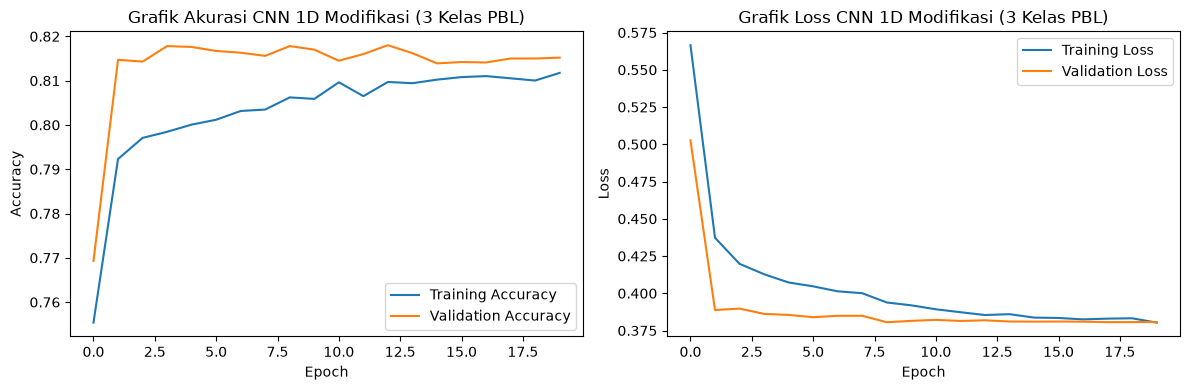

313/313 - 1s - 3ms/step - accuracy: 0.8152 - loss: 0.3807


Test Accuracy CNN 1D Modifikasi (3 Kelas): 81.52%


In [4]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_deep.history['accuracy'], label='Training Accuracy')
plt.plot(history_deep.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.title('Grafik Akurasi CNN 1D Modifikasi (3 Kelas PBL)')

plt.subplot(1, 2, 2)
plt.plot(history_deep.history['loss'], label='Training Loss')
plt.plot(history_deep.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.title('Grafik Loss CNN 1D Modifikasi (3 Kelas PBL)')

plt.tight_layout()
plt.show()

test_loss_deep, test_acc_deep = model_deep.evaluate(X_test, y_test, verbose=2)
print(f"Test Accuracy CNN 1D Modifikasi (3 Kelas): {test_acc_deep * 100:.2f}%")

Model CNN 1D yang telah dimodifikasi dengan pasangan layer konvolusi, BatchNormalization, Dropout pada setiap blok, serta callback ReduceLROnPlateau mampu mengekstrak interaksi antar fitur burnout secara stabil dan menjaga kesenjangan akurasi pelatihan serta validasi tetap kecil.

## 2. Klasifikasi Risiko Burnout Tinggi (High vs Non-High) dengan CNN 1D Ringkas

In [5]:
y_bin = (df['Burnout_Risk'] == 'High').astype(np.int32).values
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    X, y_bin, test_size=0.2, stratify=y_bin, random_state=42
)

tf.keras.utils.set_random_seed(42)
model_bin = models.Sequential([
    layers.Input(shape=(Xb_train.shape[1], 1)),
    layers.Conv1D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling1D(2),
    layers.Conv1D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling1D(2),
    layers.Conv1D(64, 3, padding='same', activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.25),
    layers.Dense(2, activation='softmax'),
])

model_bin.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_4 (Conv1D)               │ (None, 19, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 9, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 9, 64)          │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_6 (Conv1D)               │ (None, 4, 64)          │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,266 (137.76 KB)

 Trainable params: 35,266 (137.76 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model_bin.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

history_bin = model_bin.fit(
    Xb_train, yb_train,
    epochs=10,
    batch_size=128,
    validation_data=(Xb_test, yb_test),
    verbose=1,
)

Epoch 1/10


  1/313 ━━━━━━━━━━━━━━━━━━━━ 5:16 1s/step - accuracy: 0.7344 - loss: 0.6604

 14/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8170 - loss: 0.4516 

 26/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8576 - loss: 0.3597

 39/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8762 - loss: 0.3082

 50/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8859 - loss: 0.2828

... (349 outputs left out)

295/313 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9243 - loss: 0.1553

304/313 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9241 - loss: 0.1554

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9240 - loss: 0.1556

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9240 - loss: 0.1556 - val_accuracy: 0.9252 - val_loss: 0.1587


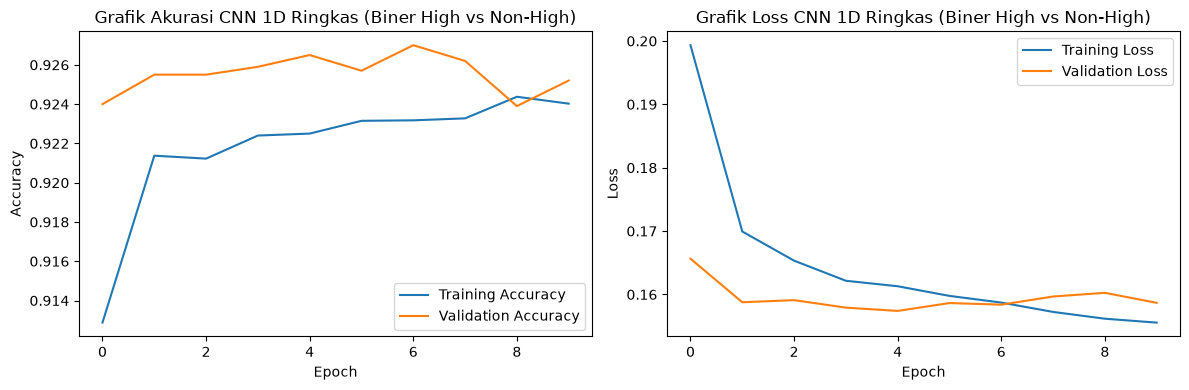

313/313 - 1s - 3ms/step - accuracy: 0.9252 - loss: 0.1587


Test Accuracy CNN 1D Ringkas (Biner): 92.52%


In [7]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_bin.history['accuracy'], label='Training Accuracy')
plt.plot(history_bin.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.title('Grafik Akurasi CNN 1D Ringkas (Biner High vs Non-High)')

plt.subplot(1, 2, 2)
plt.plot(history_bin.history['loss'], label='Training Loss')
plt.plot(history_bin.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.title('Grafik Loss CNN 1D Ringkas (Biner High vs Non-High)')

plt.tight_layout()
plt.show()

test_loss_bin, test_acc_bin = model_bin.evaluate(Xb_test, yb_test, verbose=2)
print(f"Test Accuracy CNN 1D Ringkas (Biner): {test_acc_bin * 100:.2f}%")

Model CNN 1D ringkas pada klasifikasi biner (High vs Non-High Burnout Risk) mencapai akurasi uji tinggi hanya dalam 10 epoch karena pemisahan dua kelas lebih sederhana dibandingkan klasifikasi tiga kelas.